In [1]:
!pip install pandas numpy scikit-learn matplotlib seaborn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
from google.colab import files

uploaded = files.upload()

Saving customer-churn-training (4).csv to customer-churn-training (4).csv


In [10]:
import pandas as pd

df = pd.read_csv("customer-churn-training (4).csv")

print("Customer Churn Dataset:")
display(df)

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

Customer Churn Dataset:


,customer_id,tenure_months,support_tickets,monthly_spend_inr,last_login_days,plan_type,churned
0,C001,2,4,499,21,Basic,1
1,C002,18,1,1299,2,Pro,0
2,C003,6,3,799,14,Basic,1
3,C004,30,0,1499,1,Pro,0
4,C005,11,2,999,5,Standard,0
5,C006,1,5,499,30,Basic,1
6,C007,24,1,999,3,Standard,0
7,C008,8,4,799,17,Basic,1
8,C009,15,2,1299,4,Pro,0
9,C010,4,3,499,12,Basic,1



Dataset Shape:
(12, 7)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   customer_id        12 non-null     object
 1   tenure_months      12 non-null     int64 
 2   support_tickets    12 non-null     int64 
 3   monthly_spend_inr  12 non-null     int64 
 4   last_login_days    12 non-null     int64 
 5   plan_type          12 non-null     object
 6   churned            12 non-null     int64 
dtypes: int64(5), object(2)
memory usage: 804.0+ bytes


In [11]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
customer_id          0
tenure_months        0
support_tickets      0
monthly_spend_inr    0
last_login_days      0
plan_type            0
churned              0
dtype: int64

Duplicate Records:
0


In [12]:
X = df.drop(columns=["customer_id", "churned"])
y = df["churned"]

print("Input Features:")
display(X.head())

print("\nTarget Output:")
print(y)

Input Features:


,tenure_months,support_tickets,monthly_spend_inr,last_login_days,plan_type
0,2,4,499,21,Basic
1,18,1,1299,2,Pro
2,6,3,799,14,Basic
3,30,0,1499,1,Pro
4,11,2,999,5,Standard



Target Output:
0     1
1     0
2     1
3     0
4     0
5     1
6     0
7     1
8     0
9     1
10    0
11    0
Name: churned, dtype: int64


In [13]:
numeric_features = [
    "tenure_months",
    "support_tickets",
    "monthly_spend_inr",
    "last_login_days"
]

categorical_features = ["plan_type"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Data preprocessing completed!")

Data preprocessing completed!


In [14]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

print("Logistic Regression Model Created!")

Logistic Regression Model Created!


In [15]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

predictions = cross_val_predict(
    model, X, y, cv=cv
)

accuracy = accuracy_score(y, predictions)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y,
    predictions,
    labels=[0, 1],
    target_names=["Stayed", "Churned"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y, predictions, labels=[0, 1]))

Model Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

      Stayed       1.00      1.00      1.00         7
     Churned       1.00      1.00      1.00         5

    accuracy                           1.00        12
   macro avg       1.00      1.00      1.00        12
weighted avg       1.00      1.00      1.00        12


Confusion Matrix:
[[7 0]
 [0 5]]


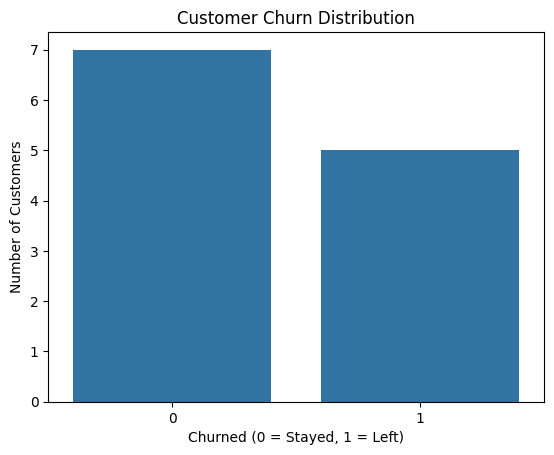

In [16]:
sns.countplot(data=df, x="churned")

plt.title("Customer Churn Distribution")
plt.xlabel("Churned (0 = Stayed, 1 = Left)")
plt.ylabel("Number of Customers")

plt.show()

In [17]:
model.fit(X, y)

new_customer = pd.DataFrame([{
    "tenure_months": 3,
    "support_tickets": 4,
    "monthly_spend_inr": 599,
    "last_login_days": 20,
    "plan_type": "Basic"
}])

prediction = model.predict(new_customer)[0]

probability = model.predict_proba(new_customer)[0][1]

if prediction == 1:
    print("Customer is likely to CHURN")
else:
    print("Customer is likely to STAY")

print("Churn Probability:", round(probability * 100, 2), "%")

Customer is likely to CHURN
Churn Probability: 94.09 %
